# Part II or the Final Project for Seminar NN in NLP about How Does Instruction Tuning Affect the Representation Space of Small LLMs?

Part I (other notebook): Training and Performance Evaluation

Part II (this notebook): Representation Space Analysis

In [ ]:
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from transformers import pipeline, AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

from tqdm.auto import tqdm

from torch.nn.functional import cosine_similarity

import os
import gc

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix

from sklearn.metrics import silhouette_score, silhouette_samples

from sklearn.decomposition import PCA

import heapq
from itertools import combinations
from scipy.optimize import linprog
from sklearn.svm import SVC

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


# Prepare Analysis Dataset

We need a fixed analysis dataset (a set of prompts) that we can then feed through every checkpoint to get a representation for that checkpoint

In [ ]:
dataset = load_dataset("databricks/databricks-dolly-15k", split="train")

split_dataset = dataset.train_test_split(test_size=0.2, seed=90)
train_dataset = split_dataset["train"]

remaining_dataset = split_dataset["test"].train_test_split(test_size=0.5, seed=90)
validation_dataset = remaining_dataset["train"]
analysis_dataset = remaining_dataset["test"]

print(len(train_dataset))
print(len(validation_dataset))
print(len(analysis_dataset))

print("Train categories:", Counter(train_dataset["category"]))
print("Validation categories:", Counter(validation_dataset["category"]))
print("Analysis categories:", Counter(analysis_dataset["category"]))

README.md:   0%|          | 0.00/8.20k [00:00<?, ?B/s]

databricks-dolly-15k.jsonl: reconstructing file:   0%|          |  0.00B / 13.1MB            

databricks-dolly-15k.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/15011 [00:00<?, ? examples/s]

12008
1501
1502
Train categories: Counter({'open_qa': 2999, 'general_qa': 1773, 'classification': 1702, 'closed_qa': 1430, 'brainstorming': 1418, 'information_extraction': 1190, 'summarization': 935, 'creative_writing': 561})
Validation categories: Counter({'open_qa': 378, 'classification': 235, 'general_qa': 219, 'closed_qa': 174, 'brainstorming': 172, 'information_extraction': 145, 'summarization': 114, 'creative_writing': 64})
Analysis categories: Counter({'open_qa': 365, 'general_qa': 199, 'classification': 199, 'brainstorming': 176, 'information_extraction': 171, 'closed_qa': 169, 'summarization': 139, 'creative_writing': 84})


In [ ]:
# basically the same function as the format_example function from the training notebook, just leave out the response
def format_analysis_example(example):
    instruction = example["instruction"].strip()
    context = example["context"].strip()

    if context:
        user_message = (f"{instruction}\n\nContext:\n{context}")
    else:
        user_message = instruction

    return [{"role": "user", "content": user_message}], user_message

# Extract Representations

In [ ]:
base_directory = "/content/drive/MyDrive/NLP_Final_Project_Instruction_Tuning/smollm2_135M_dolly"

base_model_name = "HuggingFaceTB/SmolLM2-135M"
instruct_model_name = "HuggingFaceTB/SmolLM2-135M-Instruct"

instruct_tokenizer = AutoTokenizer.from_pretrained(instruct_model_name)

config.json:   0%|          | 0.00/861 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.76k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

In [ ]:
# SmolLM2 outputs one vector for every token, but for representation analysis we need one representation per prompt
# two options: last / final prompt token (Zhao et al) or mean pooling (do both, see what works better)

@torch.no_grad()
def extract_representations(model, tokenizer, dataset, max_length, device):
    all_last_token = []
    all_mean_token = []
    labels = []
    instructions = []

    for example in tqdm(dataset):
        messages, user_message = format_analysis_example(example)
        # apply chat template without generation prompt because the assistant response should not be part of the instruction representation
        formatted_prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)
        #print(user_message)
        #print(formatted_prompt)

        # find where the character positions are of the actual user message inside the complete chat formatted prompt
        user_start = formatted_prompt.find(user_message)
        user_end = user_start + len(user_message)
        #print("user starts at character:", user_start)
        #print("user ends at character:", user_end)

        # tokenize the complete prompt that will be passed to the model
        tokenized = tokenizer(formatted_prompt, return_tensors="pt", truncation=True, max_length=max_length, add_special_tokens=False)
        input_ids = tokenized["input_ids"].to(device)
        attention_mask = tokenized["attention_mask"].to(device)

        # not used for representation extraction, just for me to see what the model outputs
        #generation_prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        #generation_inputs = tokenizer(generation_prompt, return_tensors="pt", truncation=True, max_length=max_length, add_special_tokens=False).to(device)
        #generated_ids = model.generate(**generation_inputs, max_new_tokens=100, do_sample=False)
        #generated_text = tokenizer.decode(generated_ids[0, generation_inputs["input_ids"].shape[1]:], skip_special_tokens=True)
        #print("response:", generated_text)

        # determine which token positions correspond to the actual user message
        # and tokenize: everything before the user message as well as everything up to the end of the user message
        prefix_ids = tokenizer(formatted_prompt[:user_start], add_special_tokens=False)["input_ids"]
        through_user_ids = tokenizer(formatted_prompt[:user_end], add_special_tokens=False)["input_ids"]
        user_token_start = len(prefix_ids)
        user_token_end = len(through_user_ids)
        # if the whole sequence was truncated, the end of the user message is not there anymore, therefore restrict the indices to tokens that are still there after truncating
        user_token_end = min(user_token_end, input_ids.shape[1])

        user_token_indices = torch.arange(user_token_start, user_token_end)
        user_token_ids = input_ids[0, user_token_indices.to(device)]

        # MODEL FORWARD PASS IS HERE (with output_hidden_states=True)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, output_hidden_states=True, return_dict=True)

        # outputs.hidden_states is a tuple: hidden_states[0] = embedding output; hidden_states[1] = output after transformer layer 1, and so on ...
        # shape after stacking: [hidden states, batch size, sequence length, hidden size]
        hidden_states = torch.stack(outputs.hidden_states)

        # option 1: hidden state of the final token that belongs to the actual user message
        last_index = user_token_indices[-1].item()
        last_representation = hidden_states[:, 0, last_index, :]
        # option 2: mean hidden state over all tokens that belong to the actual user message
        mean_representation = hidden_states[:, 0, user_token_indices.to(device), :].mean(dim=1)

        all_last_token.append(last_representation.cpu())
        all_mean_token.append(mean_representation.cpu())
        labels.append(example["category"])
        instructions.append(example["instruction"])

    all_last_token = torch.stack(all_last_token).numpy()
    all_mean_token = torch.stack(all_mean_token).numpy()
    labels = np.array(labels)
    instructions = np.array(instructions)

    print("FINAL SHAPES:")
    print("Last token:", all_last_token.shape)
    print("Mean token:", all_mean_token.shape)
    print("Labels:", labels.shape)
    print("Instructions:", instructions.shape)

    return all_last_token, all_mean_token, labels, instructions

In [ ]:
model_to_evaluate = AutoModelForCausalLM.from_pretrained(f"{base_directory}/checkpoint-50", dtype=torch.float32).to(device)
#model_to_evaluate = AutoModelForCausalLM.from_pretrained(base_model_name, dtype=torch.float32).to(device)
model_to_evaluate.eval() # put model in evaluation mode, so that dropout etc are disabled
last_representations, mean_representations, labels, instructions = extract_representations(model_to_evaluate, instruct_tokenizer, analysis_dataset, max_length=512, device=device)
print(last_representations.shape)
print(mean_representations.shape)
print(labels.shape)

Loading weights:   0%|          | 0/272 [00:09<?, ?it/s]

  0%|          | 0/1502 [00:00<?, ?it/s]


FINAL SHAPES:
Last token: (1502, 31, 576)
Mean token: (1502, 31, 576)
Labels: (1502,)
Instructions: (1502,)
(1502, 31, 576)
(1502, 31, 576)
(1502,)


In [ ]:
np.savez_compressed(f"{base_directory}/representations/checkpoint-50", last_token=last_representations, mean_pool=mean_representations, labels=labels, instructions=instructions)

# Global Representation Similarity by CKA (Centered Kernel Alignment)

use linear CKA, i.e. a linear kernel

introduced in the paper "Similarity of Neural Network Representation Revisited" (Kornblinth et al): they specifically define a HSIC and CKA formula, but in Table 1 they also write a simpler Formula using products and the norm which I will implement here

see this implementation for the more complicated version: https://colab.research.google.com/github/RobertTLange/code-and-blog/blob/master/10_all_cnn_cka/cka.ipynb

In [ ]:
base_directory = "/content/drive/MyDrive/NLP_Final_Project_Instruction_Tuning/smollm2_135M_dolly"
representation_dir = f"{base_directory}/representations"
files = sorted([file for file in os.listdir(representation_dir) if file.endswith(".npz")])
print(files)

first_file = np.load(os.path.join(representation_dir, files[0]))

# shape: amount of examples, layers, hidden dimension size
# i.e. one example at one layer is represented by a vector of length 576
print("Representation shape:", first_file["last_token"].shape)

# extract one layer from the one model, every row is one instruction representation
layer = 10
one_checkpoint_one_layer = first_file["last_token"][:, layer, :]
print(one_checkpoint_one_layer.shape)

['base-model.npz', 'checkpoint-10.npz', 'checkpoint-100.npz', 'checkpoint-1600.npz', 'checkpoint-400.npz', 'checkpoint-50.npz', 'checkpoint-800.npz', 'published-instruct.npz']
Representation shape: (1502, 31, 576)
(1502, 576)


In [ ]:
# this implementation is from the notebook I linked above, but the one below is from Table 1 of the paper and seems way simpler to me
# results are the same so the implementations are equivalent

import jax.numpy as jnp

def hsic(A,B):
    # hsic = Hilbert-Schmidt Independence Criterion
    m = A.shape[0]
    H = jnp.eye(m) - 1/m * jnp.ones((m,m))
    numerator = jnp.trace(A @ H @ B @ H)
    return numerator / (m-1)**2

def linear_cka(X,Y):
    # compute linear kernel
    X_kernel = X @ X.T
    Y_kernel = Y @ Y.T

    # compute frac
    frac = hsic(X_kernel, Y_kernel) / jnp.sqrt(hsic(X_kernel, X_kernel) * hsic(Y_kernel, Y_kernel))

    return frac

In [ ]:
# representaions X and Y both have shape [number of examples, hidden size] and contain the same analysis examples in the same order
# 1 means highly similar representation structure, 0 is the lowest possible

# this implementation gives the same results as the one above!

def linear_cka_simpler_and_faster(X,Y):
    # center the hidden dimensions
    X = X - X.mean(axis=0, keepdims=True)
    Y = Y - Y.mean(axis=0, keepdims=True)

    # measure similarity between representation matrices
    numerator = np.linalg.norm(X.T @ Y, ord="fro") ** 2
    denominator_x = np.linalg.norm(X.T @ X, ord="fro")
    denominator_y = np.linalg.norm(Y.T @ Y, ord="fro")

    return numerator / (denominator_x * denominator_y)

In [ ]:
models_to_evaluate = {
    "base": "base-model.npz",
    "checkpoint-10": "checkpoint-10.npz",
    "checkpoint-50": "checkpoint-50.npz",
    "checkpoint-100": "checkpoint-100.npz",
    "checkpoint-400": "checkpoint-400.npz",
    "checkpoint-800": "checkpoint-800.npz",
    "checkpoint-1600": "checkpoint-1600.npz",
    "published-instruct": "published-instruct.npz"
}

# index 0 is be the embedding output, all other indices are outputs of transformer layers
layers_to_evaluate = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]

In [ ]:
def compute_cka_table(representation_dir, model_files, selected_layers, representation_type="last_token"):
    base_data = np.load(os.path.join(representation_dir, model_files["base"]))
    base_representations = base_data[representation_type]
    base_labels = base_data["labels"]
    base_instructions = base_data["instructions"]

    results = {}
    for model_name, filename in model_files.items():
        print("Analyzing", model_name)
        data = np.load(os.path.join(representation_dir, filename))

        assert np.array_equal(data["labels"], base_labels), f"Labels do not match for {model_name}."
        assert np.array_equal(data["instructions"], base_instructions), f"Instructions do not match for {model_name}."

        representations = data[representation_type]

        model_scores = {}
        for layer in selected_layers:
            X = base_representations[:, layer, :]
            Y = representations[:, layer, :]
            model_scores[f"Layer {layer}"] = linear_cka_simpler_and_faster(X, Y)

        results[model_name] = model_scores

    cka_table = pd.DataFrame.from_dict(results, orient="index")
    cka_table.index.name = "Model"

    return cka_table

In [ ]:
cka_table = compute_cka_table(representation_dir, models_to_evaluate, layers_to_evaluate, representation_type="mean_pool")
display(cka_table.round(4))

Analyzing base
Analyzing checkpoint-10
Analyzing checkpoint-50
Analyzing checkpoint-100
Analyzing checkpoint-400
Analyzing checkpoint-800
Analyzing checkpoint-1600
Analyzing published-instruct


,Layer 0,Layer 1,Layer 2,Layer 3,Layer 4,Layer 5,Layer 6,Layer 7,Layer 8,Layer 9,...,Layer 21,Layer 22,Layer 23,Layer 24,Layer 25,Layer 26,Layer 27,Layer 28,Layer 29,Layer 30
Model,,,,,,,,,,,,,,,,,,,,,
base,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,...,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
checkpoint-10,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,...,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.9999,0.9999
checkpoint-50,1.0000,1.0000,0.9999,0.9847,0.9845,0.9844,0.9852,0.9859,0.9848,0.9862,...,0.9916,0.9918,0.9931,0.9911,0.9901,0.9896,0.9895,0.9862,0.9845,0.9777
checkpoint-100,1.0000,0.9999,0.9999,0.9908,0.9906,0.9906,0.9901,0.9896,0.9885,0.9905,...,0.9850,0.9877,0.9894,0.9873,0.9850,0.9851,0.9839,0.9792,0.9748,0.9620
checkpoint-400,1.0000,0.9998,0.9987,0.9660,0.9642,0.9637,0.9653,0.9646,0.9622,0.9664,...,0.9736,0.9807,0.9843,0.9815,0.9785,0.9790,0.9776,0.9672,0.9596,0.9416
checkpoint-800,1.0000,0.9996,0.9987,0.8226,0.8299,0.8327,0.8381,0.8402,0.8416,0.8785,...,0.9701,0.9788,0.9821,0.9787,0.9749,0.9761,0.9744,0.9639,0.9559,0.9332
checkpoint-1600,1.0000,0.9996,0.9985,0.8205,0.8297,0.8343,0.8438,0.8500,0.8525,0.8894,...,0.9684,0.9782,0.9816,0.9786,0.9748,0.9753,0.9733,0.9636,0.9560,0.9332
published-instruct,0.9996,0.9878,0.9800,0.7960,0.7989,0.8003,0.8106,0.8192,0.8191,0.8390,...,0.9630,0.9700,0.9711,0.9670,0.9601,0.9617,0.9644,0.9548,0.9524,0.9094


In [ ]:
cka_table.to_csv(f"{representation_dir}/cka_mean-pool_results.csv")

,Layer 0,Layer 1,Layer 2,Layer 3,Layer 4,Layer 5,Layer 6,Layer 7,Layer 8,Layer 9,...,Layer 21,Layer 22,Layer 23,Layer 24,Layer 25,Layer 26,Layer 27,Layer 28,Layer 29,Layer 30
Model,,,,,,,,,,,,,,,,,,,,,
base,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,...,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
checkpoint-10,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,...,0.9999,0.9999,0.9999,0.9999,0.9999,0.9999,0.9999,0.9999,0.9999,0.9998
checkpoint-50,1.0000,1.0000,1.0000,1.0000,1.0000,0.9999,0.9998,0.9996,0.9991,0.9986,...,0.9897,0.9820,0.9839,0.9813,0.9784,0.9773,0.9767,0.9735,0.9732,0.9609
checkpoint-100,1.0000,1.0000,1.0000,1.0000,0.9999,0.9997,0.9990,0.9985,0.9990,0.9988,...,0.9868,0.9793,0.9789,0.9228,0.8980,0.8945,0.9050,0.8556,0.8344,0.8582
checkpoint-400,1.0000,0.9999,0.9998,0.9997,0.9993,0.9984,0.9986,0.9971,0.9976,0.9975,...,0.9809,0.9751,0.9728,0.8904,0.8723,0.8672,0.8802,0.8140,0.7871,0.7987
checkpoint-800,1.0000,0.9999,0.9998,0.9996,0.9990,0.9975,0.9984,0.9970,0.9964,0.9956,...,0.9820,0.9770,0.9737,0.9073,0.8974,0.8903,0.8999,0.8491,0.8304,0.8115
checkpoint-1600,1.0000,0.9999,0.9998,0.9996,0.9990,0.9970,0.9982,0.9965,0.9960,0.9953,...,0.9818,0.9789,0.9752,0.9134,0.9034,0.8972,0.9062,0.8607,0.8456,0.8171
published-instruct,0.9997,0.9952,0.9953,0.9842,0.9847,0.9854,0.9858,0.9830,0.9817,0.9830,...,0.9638,0.9349,0.9130,0.8551,0.8486,0.8455,0.8416,0.8152,0.7967,0.7109


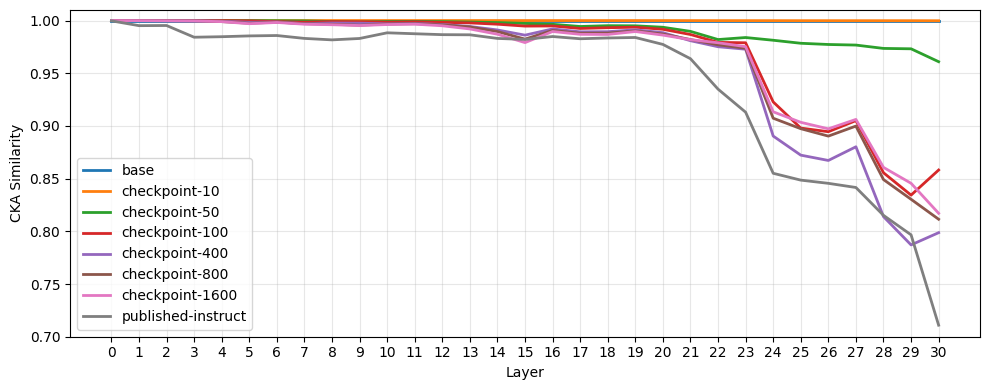

In [ ]:
cka_table = pd.read_csv(f"{representation_dir}/cka_last-token_results.csv", index_col=0)
display(cka_table.round(4))

layers = range(len(cka_table.columns))
plt.figure(figsize=(10,4))

for model_name, row in cka_table.iterrows():
      plt.plot(layers, row.values, linewidth=2, label=model_name)

plt.xlabel("Layer")
plt.ylabel("CKA Similarity")
plt.xticks(layers)
plt.ylim(0.7, 1.01)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(f"{representation_dir}/cka_last-token_results.png", dpi=600, bbox_inches="tight")
plt.show()

# Task Seperability by Probing

In [ ]:
base_directory = "/content/drive/MyDrive/NLP_Final_Project_Instruction_Tuning/smollm2_135M_dolly"
representation_dir = f"{base_directory}/representations"

base_data = np.load(os.path.join(representation_dir, "checkpoint-1600.npz"))
base_representations = base_data["last_token"]
base_labels = base_data["labels"]
base_instructions = base_data["instructions"]

In [ ]:
# make train_test_split of indices, because we cannot simply split the analysis dataset anymore because we already ran it through the model to get representations
indices = np.arange(len(base_labels))
probe_training_indices, probe_test_indices = train_test_split(indices, test_size=0.2, random_state=90, stratify=base_labels)
print(len(probe_training_indices))
print(len(probe_test_indices))

1201
301


In [ ]:
def linear_probe(representations, labels, train_indices, test_indices):
    # the expected shape for representations is [number of examples, hidden size] and not the layer dimension
    X_train = representations[train_indices]
    X_test = representations[test_indices]
    y_train = labels[train_indices]
    y_test = labels[test_indices]

    probe_classifier = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", solver="lbfgs"))
    #probe_classifier = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64,32), max_iter=300, random_state=90))

    probe_classifier.fit(X_train, y_train)

    #print(probe_classifier.predict_proba(X_test[:1])) # print probabilities for one example to check if it works
    y_pred = probe_classifier.predict(X_test)
    metrics = {
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred), # mean recall across classes
        "f1_macro": f1_score(y_test, y_pred, average="macro"), # F1 separately for every category
        "f1_weighted": f1_score(y_test, y_pred, average="weighted")
    }

    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0) # target_names=probe_classifier.classes_,
    cf_matrix = confusion_matrix(y_test, y_pred)

    return metrics, report, cf_matrix

In [ ]:
# test with the base model
layer = 15
X = base_representations[:, layer, :]
metrics, report, cf_matrix = linear_probe(X, base_labels, probe_training_indices, probe_test_indices)
print(metrics)
print(report)

class_names = np.unique(base_labels)
confusion_table = pd.DataFrame(cf_matrix, index=class_names, columns=class_names)
confusion_table.index.name = "Actual"
confusion_table.columns.name = "Predicted"
display(confusion_table)

{'accuracy': 0.5780730897009967, 'balanced_accuracy': np.float64(0.5477124582709796), 'f1_macro': 0.5526968559579979, 'f1_weighted': 0.5800338359920639}
{'brainstorming': {'precision': 0.5806451612903226, 'recall': 0.5142857142857142, 'f1-score': 0.5454545454545454, 'support': 35.0}, 'classification': {'precision': 0.8292682926829268, 'recall': 0.85, 'f1-score': 0.8395061728395061, 'support': 40.0}, 'closed_qa': {'precision': 0.3142857142857143, 'recall': 0.3235294117647059, 'f1-score': 0.3188405797101449, 'support': 34.0}, 'creative_writing': {'precision': 0.7142857142857143, 'recall': 0.5882352941176471, 'f1-score': 0.6451612903225806, 'support': 17.0}, 'general_qa': {'precision': 0.5609756097560976, 'recall': 0.575, 'f1-score': 0.5679012345679012, 'support': 40.0}, 'information_extraction': {'precision': 0.3783783783783784, 'recall': 0.4117647058823529, 'f1-score': 0.39436619718309857, 'support': 34.0}, 'open_qa': {'precision': 0.7361111111111112, 'recall': 0.726027397260274, 'f1-sc

Predicted,brainstorming,classification,closed_qa,creative_writing,general_qa,information_extraction,open_qa,summarization
Actual,,,,,,,,
brainstorming,18,2,0,1,4,1,9,0
classification,1,34,0,0,0,3,2,0
closed_qa,0,1,11,0,0,15,1,6
creative_writing,1,2,0,10,2,0,1,1
general_qa,7,1,1,1,23,0,6,1
information_extraction,0,1,10,0,0,14,0,9
open_qa,4,0,0,2,12,0,53,2
summarization,0,0,13,0,0,4,0,11


In [ ]:
models_to_evaluate = {
    "base": "base-model.npz",
    "checkpoint-10": "checkpoint-10.npz",
    "checkpoint-50": "checkpoint-50.npz",
    "checkpoint-100": "checkpoint-100.npz",
    "checkpoint-400": "checkpoint-400.npz",
    "checkpoint-800": "checkpoint-800.npz",
    "checkpoint-1600": "checkpoint-1600.npz",
    "published-instruct": "published-instruct.npz"
}

# index 0 is be the embedding output, all other indices are outputs of transformer layers
#layers_to_evaluate = [0, 1, 10, 15, 20, 22, 24, 26, 28, 30]
layers_to_evaluate = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]

In [ ]:
def run_all_linear_probes(representation_dir, model_files, selected_layers, train_indices, test_indices, representation_type="last_token"):
    results = []

    for model_name, filename in model_files.items():
        print("Probing", model_name)
        data = np.load(os.path.join(representation_dir, filename))
        representations = data[representation_type]
        labels = data["labels"]

        for layer in selected_layers:
            X = representations[:, layer, :]
            metrics, report, _ = linear_probe(X, labels, train_indices, test_indices)
            results.append({
                "model": model_name,
                "layer": layer,
                "accuracy": metrics["accuracy"],
                "balanced_accuracy": metrics["balanced_accuracy"],
                "f1_macro": metrics["f1_macro"],
                "f1_weighted": metrics["f1_weighted"]
            })
            print(f"Layer {layer}: {metrics}")
            #print(report)

    results_table = pd.DataFrame(results)
    return results_table

In [ ]:
probe_results = run_all_linear_probes(representation_dir, models_to_evaluate, layers_to_evaluate, probe_training_indices, probe_test_indices, representation_type="last_token")
pd.set_option('display.max_rows', 500)
display(probe_results)

Probing base
Layer 0: {'accuracy': 0.29900332225913623, 'balanced_accuracy': np.float64(0.2922013497179694), 'f1_macro': 0.21286190752757034, 'f1_weighted': 0.22469814042939226}
Layer 1: {'accuracy': 0.4019933554817276, 'balanced_accuracy': np.float64(0.37908081040635433), 'f1_macro': 0.36928937869709594, 'f1_weighted': 0.4004183901346265}
Layer 2: {'accuracy': 0.45514950166112955, 'balanced_accuracy': np.float64(0.4344332767353517), 'f1_macro': 0.4307377891182722, 'f1_weighted': 0.45958041494570395}
Layer 3: {'accuracy': 0.42524916943521596, 'balanced_accuracy': np.float64(0.4085821486128698), 'f1_macro': 0.4055409397390372, 'f1_weighted': 0.4310946500541566}
Layer 4: {'accuracy': 0.4850498338870432, 'balanced_accuracy': np.float64(0.45469703292275815), 'f1_macro': 0.4466847845684585, 'f1_weighted': 0.4872397752535567}
Layer 5: {'accuracy': 0.48172757475083056, 'balanced_accuracy': np.float64(0.46366733337170485), 'f1_macro': 0.45387081359066284, 'f1_weighted': 0.4847244978649798}


KeyboardInterrupt: 

In [ ]:
probe_results.to_csv(f"{representation_dir}/logreg_last-token_probe_results.csv", index=False)

In [ ]:
probe_results = pd.read_csv(f"{representation_dir}/mlp_last-token_probe_results.csv")
#display(probe_results)

In [ ]:
model_order = ["base", "checkpoint-10", "checkpoint-50", "checkpoint-100", "checkpoint-400", "checkpoint-800", "checkpoint-1600", "published-instruct"]

accuracy_table = probe_results.pivot(index="model", columns="layer", values="accuracy")
accuracy_table = accuracy_table.reindex(model_order)
accuracy_table.columns = [f"Layer {layer}" for layer in accuracy_table.columns]
display(accuracy_table.round(4))

,Layer 0,Layer 1,Layer 2,Layer 3,Layer 4,Layer 5,Layer 6,Layer 7,Layer 8,Layer 9,...,Layer 21,Layer 22,Layer 23,Layer 24,Layer 25,Layer 26,Layer 27,Layer 28,Layer 29,Layer 30
model,,,,,,,,,,,,,,,,,,,,,
base,0.3688,0.4020,0.4551,0.4884,0.4983,0.4884,0.5249,0.5282,0.4983,0.5681,...,0.5316,0.5615,0.5515,0.5748,0.5847,0.5548,0.6113,0.5648,0.5714,0.5482
checkpoint-10,0.3688,0.4186,0.4219,0.4917,0.5050,0.4917,0.4983,0.5017,0.5116,0.5415,...,0.5415,0.5714,0.5947,0.5748,0.5880,0.5515,0.5847,0.5615,0.5714,0.5349
checkpoint-50,0.2924,0.3953,0.4452,0.4684,0.4950,0.4950,0.4917,0.5216,0.5083,0.5748,...,0.5449,0.5349,0.5648,0.5482,0.5415,0.5615,0.5515,0.5814,0.5548,0.5615
checkpoint-100,0.2791,0.4053,0.4585,0.4684,0.5050,0.4751,0.5249,0.5482,0.5349,0.5382,...,0.5781,0.5515,0.5615,0.5781,0.5947,0.5847,0.5714,0.5615,0.5880,0.5681
checkpoint-400,0.2757,0.4286,0.4252,0.4850,0.5050,0.4784,0.5316,0.4950,0.5249,0.5050,...,0.5781,0.5714,0.5781,0.5382,0.5814,0.5581,0.5980,0.5648,0.5748,0.5781
checkpoint-800,0.3688,0.3987,0.3953,0.4917,0.5083,0.4784,0.5249,0.5017,0.5083,0.4950,...,0.5581,0.5515,0.5814,0.5714,0.5681,0.5581,0.6013,0.5714,0.5615,0.5748
checkpoint-1600,0.3688,0.4086,0.4419,0.4452,0.4950,0.4718,0.5050,0.5183,0.4983,0.5183,...,0.5714,0.5415,0.5415,0.5781,0.5681,0.5449,0.6047,0.5581,0.5648,0.5781
published-instruct,0.3721,0.4053,0.4452,0.4585,0.5216,0.5083,0.4585,0.5116,0.5249,0.5249,...,0.5449,0.5615,0.5714,0.5548,0.5681,0.5548,0.5980,0.5449,0.5781,0.5847


In [ ]:
balanced_accuracy_table = probe_results.pivot(index="model", columns="layer", values="balanced_accuracy")
balanced_accuracy_table = balanced_accuracy_table.reindex(model_order)
balanced_accuracy_table.columns = [f"Layer {layer}" for layer in balanced_accuracy_table.columns]
display(balanced_accuracy_table.round(4))

,Layer 0,Layer 1,Layer 2,Layer 3,Layer 4,Layer 5,Layer 6,Layer 7,Layer 8,Layer 9,...,Layer 21,Layer 22,Layer 23,Layer 24,Layer 25,Layer 26,Layer 27,Layer 28,Layer 29,Layer 30
model,,,,,,,,,,,,,,,,,,,,,
base,0.2744,0.3049,0.4173,0.4514,0.4468,0.4556,0.4881,0.4856,0.4543,0.5127,...,0.5058,0.5440,0.5349,0.5389,0.5490,0.5240,0.5844,0.5310,0.5478,0.5199
checkpoint-10,0.2897,0.3213,0.3797,0.4590,0.4803,0.4548,0.4527,0.4720,0.4774,0.5035,...,0.5197,0.5448,0.5575,0.5426,0.5516,0.5296,0.5614,0.5310,0.5496,0.4993
checkpoint-50,0.2832,0.3040,0.3947,0.4329,0.4560,0.4486,0.4490,0.4780,0.4726,0.5344,...,0.5241,0.5150,0.5470,0.5174,0.5064,0.5187,0.5152,0.5541,0.5229,0.5321
checkpoint-100,0.2849,0.3078,0.4150,0.4161,0.4613,0.4329,0.4726,0.4955,0.4787,0.4985,...,0.5513,0.5294,0.5431,0.5482,0.5600,0.5451,0.5399,0.5368,0.5426,0.5390
checkpoint-400,0.2846,0.3349,0.3707,0.4484,0.4760,0.4330,0.4768,0.4424,0.4647,0.4670,...,0.5413,0.5341,0.5502,0.5136,0.5448,0.5171,0.5624,0.5314,0.5360,0.5489
checkpoint-800,0.2721,0.2994,0.3724,0.4519,0.4752,0.4379,0.4697,0.4421,0.4563,0.4487,...,0.5305,0.5241,0.5519,0.5409,0.5310,0.5035,0.5567,0.5298,0.5320,0.5454
checkpoint-1600,0.2886,0.3146,0.3922,0.4077,0.4710,0.4314,0.4645,0.4665,0.4485,0.4738,...,0.5496,0.5217,0.5179,0.5395,0.5292,0.4977,0.5563,0.5242,0.5295,0.5497
published-instruct,0.2754,0.3058,0.3931,0.3994,0.4731,0.4508,0.4138,0.4780,0.4843,0.4978,...,0.5000,0.5234,0.5458,0.5064,0.5233,0.5158,0.5528,0.5166,0.5340,0.5501


In [ ]:
f1_macro_table = probe_results.pivot(index="model", columns="layer", values="f1_macro")
f1_macro_table = f1_macro_table.reindex(model_order)
f1_macro_table.columns = [f"Layer {layer}" for layer in f1_macro_table.columns]
display(f1_macro_table.round(4))

,Layer 0,Layer 1,Layer 2,Layer 3,Layer 4,Layer 5,Layer 6,Layer 7,Layer 8,Layer 9,...,Layer 21,Layer 22,Layer 23,Layer 24,Layer 25,Layer 26,Layer 27,Layer 28,Layer 29,Layer 30
model,,,,,,,,,,,,,,,,,,,,,
base,0.2129,0.3693,0.4307,0.4055,0.4467,0.4539,0.5032,0.5081,0.5012,0.4992,...,0.5704,0.5307,0.4814,0.5065,0.5081,0.5020,0.5251,0.5098,0.5171,0.5064
checkpoint-10,0.2129,0.3664,0.4274,0.4055,0.4499,0.4510,0.5001,0.5116,0.5007,0.4945,...,0.5742,0.5322,0.4963,0.5078,0.5136,0.5045,0.5144,0.5121,0.5194,0.5068
checkpoint-50,0.2135,0.3733,0.4273,0.4134,0.4576,0.4549,0.4802,0.5027,0.5101,0.4889,...,0.5880,0.5403,0.5004,0.4794,0.5207,0.5397,0.5373,0.5323,0.5277,0.4984
checkpoint-100,0.2129,0.3827,0.4347,0.4184,0.4497,0.4590,0.4811,0.4987,0.5125,0.4921,...,0.5759,0.5582,0.5324,0.5179,0.5385,0.5462,0.5256,0.5209,0.5204,0.5369
checkpoint-400,0.2129,0.3801,0.4269,0.4285,0.4540,0.4370,0.4884,0.5208,0.5037,0.4768,...,0.5937,0.5529,0.5302,0.5288,0.5233,0.5571,0.5233,0.4868,0.5028,0.5048
checkpoint-800,0.2135,0.3803,0.4305,0.4206,0.4420,0.4469,0.4701,0.5267,0.5231,0.4830,...,0.5752,0.5472,0.5310,0.5240,0.5301,0.5275,0.5171,0.4899,0.4896,0.5296
checkpoint-1600,0.2129,0.3781,0.4382,0.4219,0.4429,0.4442,0.4871,0.5314,0.4971,0.4776,...,0.5801,0.5444,0.5183,0.5404,0.5145,0.5133,0.5001,0.4718,0.4680,0.5155
published-instruct,0.2192,0.3817,0.4263,0.4174,0.4963,0.4743,0.4778,0.4736,0.5042,0.4958,...,0.5579,0.5534,0.5182,0.5238,0.5278,0.5107,0.5412,0.5497,0.5411,0.5168


In [ ]:
f1_weighted_table = probe_results.pivot(index="model", columns="layer", values="f1_weighted")
f1_weighted_table = f1_weighted_table.reindex(model_order)
f1_weighted_table.columns = [f"Layer {layer}" for layer in f1_weighted_table.columns]
display(f1_weighted_table.round(4))

,Layer 0,Layer 1,Layer 2,Layer 3,Layer 4,Layer 5,Layer 6,Layer 7,Layer 8,Layer 9,...,Layer 21,Layer 22,Layer 23,Layer 24,Layer 25,Layer 26,Layer 27,Layer 28,Layer 29,Layer 30
model,,,,,,,,,,,,,,,,,,,,,
base,0.2247,0.4004,0.4596,0.4311,0.4872,0.4847,0.5273,0.5347,0.5228,0.5133,...,0.5823,0.5569,0.5155,0.5345,0.5335,0.5364,0.5491,0.5454,0.5514,0.5362
checkpoint-10,0.2247,0.3969,0.4567,0.4311,0.4900,0.4809,0.5243,0.5376,0.5231,0.5094,...,0.5832,0.5572,0.5328,0.5370,0.5395,0.5400,0.5389,0.5421,0.5549,0.5369
checkpoint-50,0.2252,0.4033,0.4571,0.4373,0.4993,0.4840,0.5087,0.5272,0.5319,0.5066,...,0.5989,0.5452,0.5200,0.5138,0.5441,0.5611,0.5578,0.5527,0.5539,0.5281
checkpoint-100,0.2247,0.4098,0.4631,0.4438,0.4896,0.4875,0.5087,0.5235,0.5359,0.5097,...,0.5920,0.5748,0.5520,0.5484,0.5642,0.5695,0.5485,0.5396,0.5384,0.5557
checkpoint-400,0.2247,0.4129,0.4570,0.4536,0.4929,0.4631,0.5111,0.5477,0.5371,0.5027,...,0.6019,0.5648,0.5544,0.5500,0.5491,0.5764,0.5562,0.5085,0.5249,0.5299
checkpoint-800,0.2252,0.4127,0.4607,0.4490,0.4808,0.4729,0.4939,0.5532,0.5516,0.5058,...,0.5931,0.5597,0.5548,0.5463,0.5540,0.5496,0.5481,0.5244,0.5166,0.5537
checkpoint-1600,0.2247,0.4088,0.4669,0.4502,0.4801,0.4706,0.5102,0.5623,0.5306,0.5073,...,0.5922,0.5615,0.5483,0.5668,0.5416,0.5368,0.5362,0.5046,0.5092,0.5481
published-instruct,0.2309,0.4163,0.4565,0.4485,0.5215,0.5059,0.5032,0.4975,0.5179,0.5102,...,0.5617,0.5692,0.5428,0.5522,0.5565,0.5318,0.5629,0.5686,0.5638,0.5424


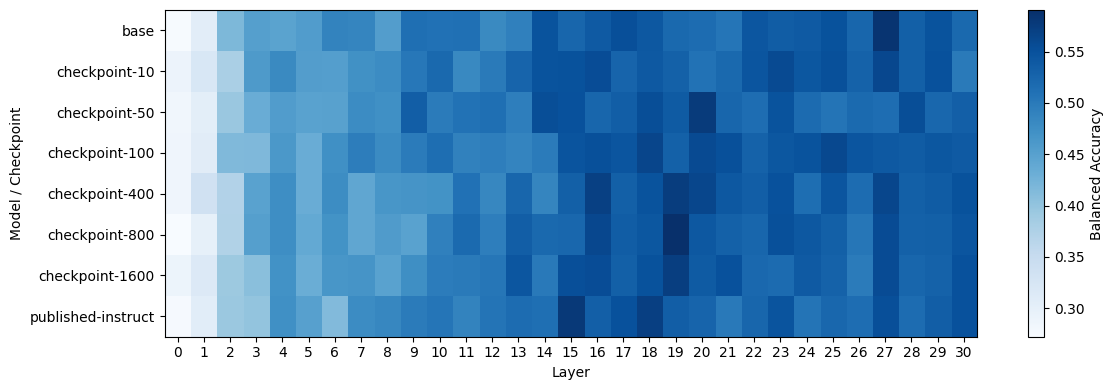

In [ ]:
# show probing results with a heatmap, because table and line plot does not look that good

balanced_accuracy_table.columns = [int(col.replace("Layer ", "")) for col in balanced_accuracy_table.columns]

fig, ax = plt.subplots(figsize=(12,4))
im = ax.imshow(balanced_accuracy_table.values, aspect="auto", cmap="Blues") # v min and v max?

ax.set_xlabel("Layer")
ax.set_ylabel("Model / Checkpoint")

ax.set_xticks(np.arange(len(balanced_accuracy_table.columns)))
ax.set_xticklabels(balanced_accuracy_table.columns)
ax.set_yticks(np.arange(len(balanced_accuracy_table.index)))
ax.set_yticklabels(balanced_accuracy_table.index)

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Balanced Accuracy")

plt.tight_layout()
plt.savefig(f"{representation_dir}/probing_mlp_balanced-accuracy_last-token_heatmap.png", dpi=600, bbox_inches="tight")
plt.show()

# Silhouette Score

In [ ]:
# in the end this implementation was not used
def compute_silhouette(representations, labels, metric="cosine"):
    overall_score = silhouette_score(representations, labels, metric=metric)
    sample_scores = silhouette_samples(representations, labels, metric=metric)
    category_scores = {label: sample_scores[labels == label].mean() for label in np.unique(labels)}
    return overall_score, category_scores

In [ ]:
def run_silhouette_analysis(representation_dir, model_files, selected_layers, representation_type="last_token", metric="cosine"):
    base_data = np.load(os.path.join(representation_dir, model_files["base"]))
    reference_labels = base_data["labels"]
    reference_instructions = base_data["instructions"]

    results = []

    for model_name, filename in model_files.items():
        print("Silhouette score for", model_name)
        data = np.load(os.path.join(representation_dir, filename))

        assert np.array_equal(data["labels"], reference_labels), f"Labels differ for {model_name}."
        assert np.array_equal(data["instructions"], reference_instructions), f"Instructions differ for {model_name}."

        representations = data[representation_type]

        for layer in selected_layers:
            X = representations[:, layer, :]
            #score = silhouette_score(X, reference_labels, metric=metric)
            score, sample_scores = compute_silhouette(X, reference_labels, metric=metric)
            results.append({"model": model_name, "layer": layer, "silhouette": score})
            print(f"Layer {layer}: {sample_scores}")

    return pd.DataFrame(results)

In [ ]:
silhouette_results = run_silhouette_analysis(representation_dir, models_to_evaluate, layers_to_evaluate, representation_type="last_token", metric="cosine")
silhouette_table = silhouette_results.pivot(index="model", columns="layer", values="silhouette")
silhouette_table = silhouette_table.reindex(model_order)
silhouette_table.columns = [f"Layer {layer}" for layer in silhouette_table.columns]
display(silhouette_table.round(4))

Silhouette score for base
Layer 0: {np.str_('brainstorming'): np.float32(-0.5548304), np.str_('classification'): np.float32(-0.10825211), np.str_('closed_qa'): np.float32(-0.2713452), np.str_('creative_writing'): np.float32(-0.62471014), np.str_('general_qa'): np.float32(0.60958886), np.str_('information_extraction'): np.float32(0.068313286), np.str_('open_qa'): np.float32(-0.57608616), np.str_('summarization'): np.float32(-0.12711518)}
Layer 1: {np.str_('brainstorming'): np.float32(-0.5413651), np.str_('classification'): np.float32(-0.14058842), np.str_('closed_qa'): np.float32(-0.2186357), np.str_('creative_writing'): np.float32(-0.58116674), np.str_('general_qa'): np.float32(0.6448661), np.str_('information_extraction'): np.float32(0.036669977), np.str_('open_qa'): np.float32(-0.59892577), np.str_('summarization'): np.float32(-0.07713695)}
Layer 2: {np.str_('brainstorming'): np.float32(-0.5001164), np.str_('classification'): np.float32(-0.20503522), np.str_('closed_qa'): np.float32(

,Layer 0,Layer 1,Layer 2,Layer 3,Layer 4,Layer 5,Layer 6,Layer 7,Layer 8,Layer 9,...,Layer 21,Layer 22,Layer 23,Layer 24,Layer 25,Layer 26,Layer 27,Layer 28,Layer 29,Layer 30
model,,,,,,,,,,,,,,,,,,,,,
base,-0.2080,-0.2022,-0.1924,-0.1904,-0.1838,-0.1668,-0.1559,-0.1460,-0.1342,-0.1465,...,-0.0566,-0.0520,-0.0510,-0.0453,-0.0473,-0.0429,-0.0385,-0.0303,-0.0291,-0.0956
checkpoint-10,-0.2080,-0.2022,-0.1924,-0.1904,-0.1837,-0.1668,-0.1559,-0.1461,-0.1343,-0.1468,...,-0.0572,-0.0530,-0.0522,-0.0461,-0.0481,-0.0437,-0.0394,-0.0312,-0.0300,-0.0966
checkpoint-50,-0.2080,-0.2023,-0.1923,-0.1901,-0.1831,-0.1664,-0.1555,-0.1472,-0.1362,-0.1501,...,-0.0628,-0.0638,-0.0663,-0.0614,-0.0626,-0.0576,-0.0540,-0.0476,-0.0467,-0.1116
checkpoint-100,-0.2080,-0.2025,-0.1925,-0.1902,-0.1828,-0.1654,-0.1544,-0.1468,-0.1368,-0.1510,...,-0.0642,-0.0673,-0.0714,-0.0778,-0.0832,-0.0790,-0.0739,-0.0725,-0.0705,-0.1232
checkpoint-400,-0.2081,-0.2024,-0.1925,-0.1897,-0.1809,-0.1616,-0.1539,-0.1467,-0.1376,-0.1511,...,-0.0619,-0.0674,-0.0719,-0.0786,-0.0796,-0.0771,-0.0729,-0.0678,-0.0654,-0.1145
checkpoint-800,-0.2081,-0.2021,-0.1926,-0.1896,-0.1801,-0.1601,-0.1542,-0.1473,-0.1373,-0.1505,...,-0.0645,-0.0687,-0.0737,-0.0808,-0.0809,-0.0790,-0.0746,-0.0691,-0.0671,-0.1299
checkpoint-1600,-0.2081,-0.2021,-0.1921,-0.1892,-0.1796,-0.1588,-0.1528,-0.1459,-0.1357,-0.1490,...,-0.0630,-0.0677,-0.0733,-0.0841,-0.0842,-0.0825,-0.0785,-0.0746,-0.0728,-0.1434
published-instruct,-0.2074,-0.1995,-0.1900,-0.1881,-0.1776,-0.1624,-0.1556,-0.1530,-0.1448,-0.1580,...,-0.0660,-0.0649,-0.0602,-0.0673,-0.0655,-0.0593,-0.0561,-0.0544,-0.0598,-0.0902


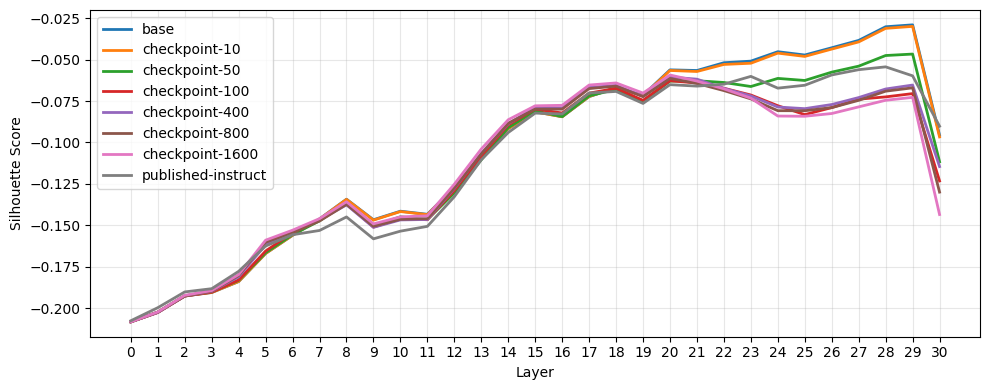

In [ ]:
# line plot: looks super similar to CKA and all checkpoints are super similar as well...

layers = range(len(silhouette_table.columns))
plt.figure(figsize=(10,4))

for model_name, row in silhouette_table.iterrows():
      plt.plot(layers, row.values, linewidth=2, label=model_name)

plt.xlabel("Layer")
plt.ylabel("Silhouette Score")
plt.xticks(layers)
#plt.ylim(0.7, 1.01)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
#plt.savefig(f"{representation_dir}/silhouette-score_last-token_results.png", dpi=600, bbox_inches="tight")
plt.show()

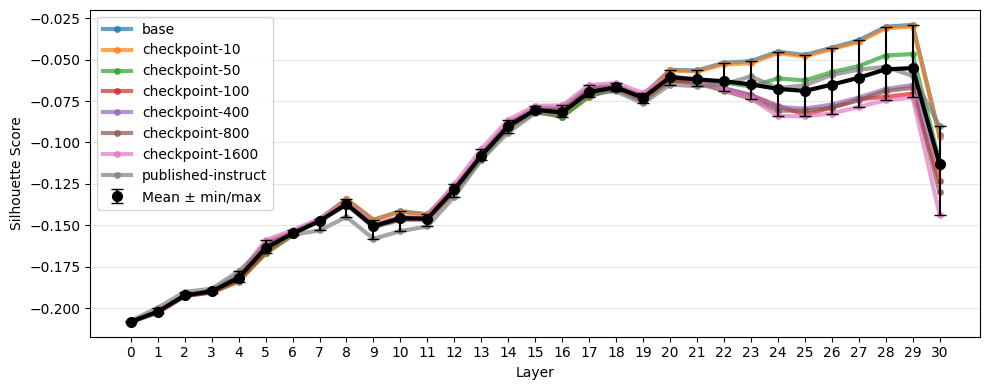

In [ ]:
# point range plot

#silhouette_table.columns = [int(col.replace("Layer ", "")) for col in silhouette_table.columns]

layers = np.arange(len(silhouette_table.columns))

means = silhouette_table.mean(axis=0).values
minimums = silhouette_table.min(axis=0).values
maximums = silhouette_table.max(axis=0).values

lower_errors = means - minimums
upper_errors = maximums - means
errors = np.vstack([lower_errors, upper_errors])

fig, ax = plt.subplots(figsize=(10, 4))

# plot individual checkpoint lines: rather faint lines
for model_name, row in silhouette_table.iterrows():
    ax.plot(layers, row.values, marker="o", markersize=4, linewidth=3, alpha=0.7, label=model_name, zorder=1)

# plot mean line
ax.plot(layers, means, linewidth=3, color="black", zorder=3)
# plot mean dots with min and max strokes
ax.errorbar(layers, means, yerr=errors, fmt="o", color="black", ecolor="black", elinewidth=1.5, capsize=4, markersize=7, zorder=4, label="Mean ± min/max")

ax.set_xlabel("Layer")
ax.set_ylabel("Silhouette Score")
ax.set_xticks(layers)
ax.set_xticklabels(silhouette_table.columns)
ax.grid(axis="y", alpha=0.3)
#ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.legend()
plt.tight_layout()
plt.savefig(f"{representation_dir}/silhouette-score_last-token_results.png", dpi=600, bbox_inches="tight")
plt.show()


# Visualization with PCA

In [ ]:
def plot_pca(representations, labels, model_name, layer):
    pca = PCA(n_components=2)
    reduced_representations = pca.fit_transform(representations)

    unique_labels = np.unique(labels)

    plt.figure(figsize=(10, 7))

    for label in unique_labels:
        mask = labels == label
        #plt.scatter(reduced_representations[mask, 0], reduced_representations[mask, 1], label=label, alpha=0.7, s=25)
        plt.scatter(reduced_representations[mask, 0], reduced_representations[mask, 1], label=label, alpha=0.5, s=20)

    explained_variance = pca.explained_variance_ratio_.sum()

    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}% variance)")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}% variance)")
    plt.title(f"PCA of representations — {model_name}, layer {layer}\nExplained variance by first two PCs: {explained_variance * 100:.2f}%")
    plt.legend(title="Instruction category", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    return reduced_representations, pca

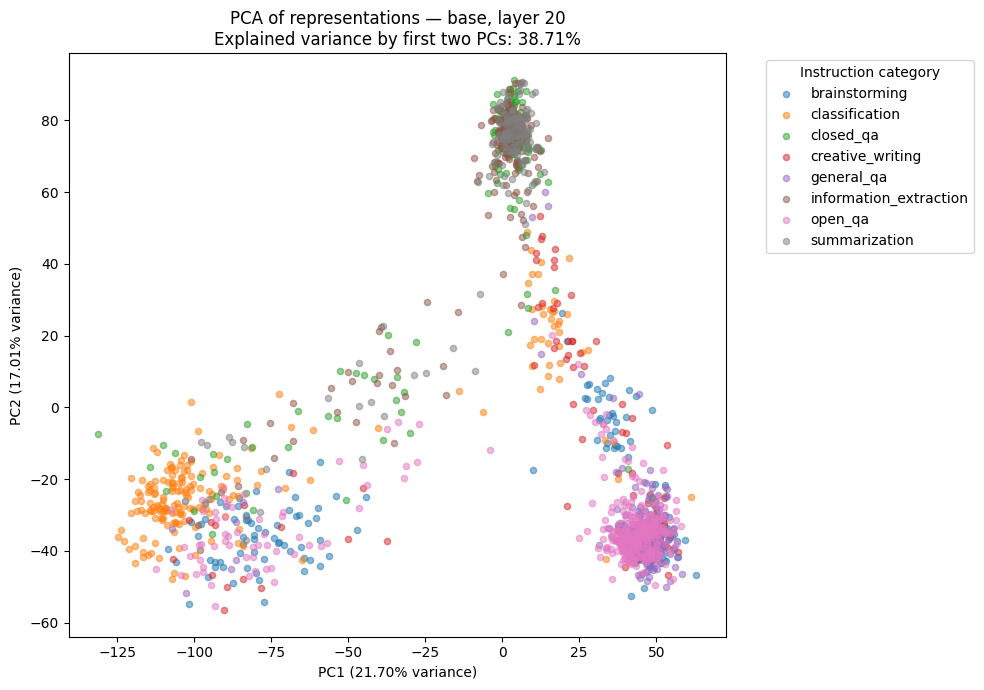

In [ ]:
base_directory = "/content/drive/MyDrive/NLP_Final_Project_Instruction_Tuning/smollm2_135M_dolly"
representation_dir = f"{base_directory}/representations"

base_data = np.load(os.path.join(representation_dir, "base-model.npz"))
base_representations = base_data["last_token"]
base_labels = base_data["labels"]

layer = 20
X = base_representations[:, layer, :]
reduced_representations, pca = plot_pca(X, base_labels, "base", layer)

In [ ]:
def plot_pca_grid(representation_dir, model_files, selected_models, selected_layers, representation_type="last_token"):
    first_data = np.load(os.path.join(representation_dir, model_files[selected_models[0]]))
    labels = first_data["labels"]
    unique_labels = np.unique(labels)

    fig, axes = plt.subplots(len(selected_models), len(selected_layers), figsize=(5 * len(selected_layers), 4 * len(selected_models)), squeeze=False)

    legend_handles = []
    legend_labels = []

    for row, model_name in enumerate(selected_models):
        data = np.load(os.path.join(representation_dir, model_files[model_name]))
        representations = data[representation_type]

        assert np.array_equal(data["labels"], labels), f"Labels differ for {model_name}."

        for col, layer in enumerate(selected_layers):
            ax = axes[row, col]
            X = representations[:, layer, :]

            pca = PCA(n_components=2)
            reduced_representations = pca.fit_transform(X)

            for label in unique_labels:
                mask = labels == label
                scatter = ax.scatter(reduced_representations[mask, 0], reduced_representations[mask, 1], label=label, alpha=0.5, s=15)

                if row == 0 and col == 0:
                    legend_handles.append(scatter)
                    legend_labels.append(label)

            ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
            ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")

            if row == 0:
                ax.set_title(f"Layer {layer}")

            if col == 0:
                ax.text(-0.25, 0.5, model_name, transform=ax.transAxes, rotation=90, va="center", ha="center", fontsize=12, fontweight="bold")

    fig.legend(legend_handles, legend_labels, title="Instruction category", loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=len(unique_labels))
    fig.suptitle("PCA of instruction representations", fontsize=14, y=1.08)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

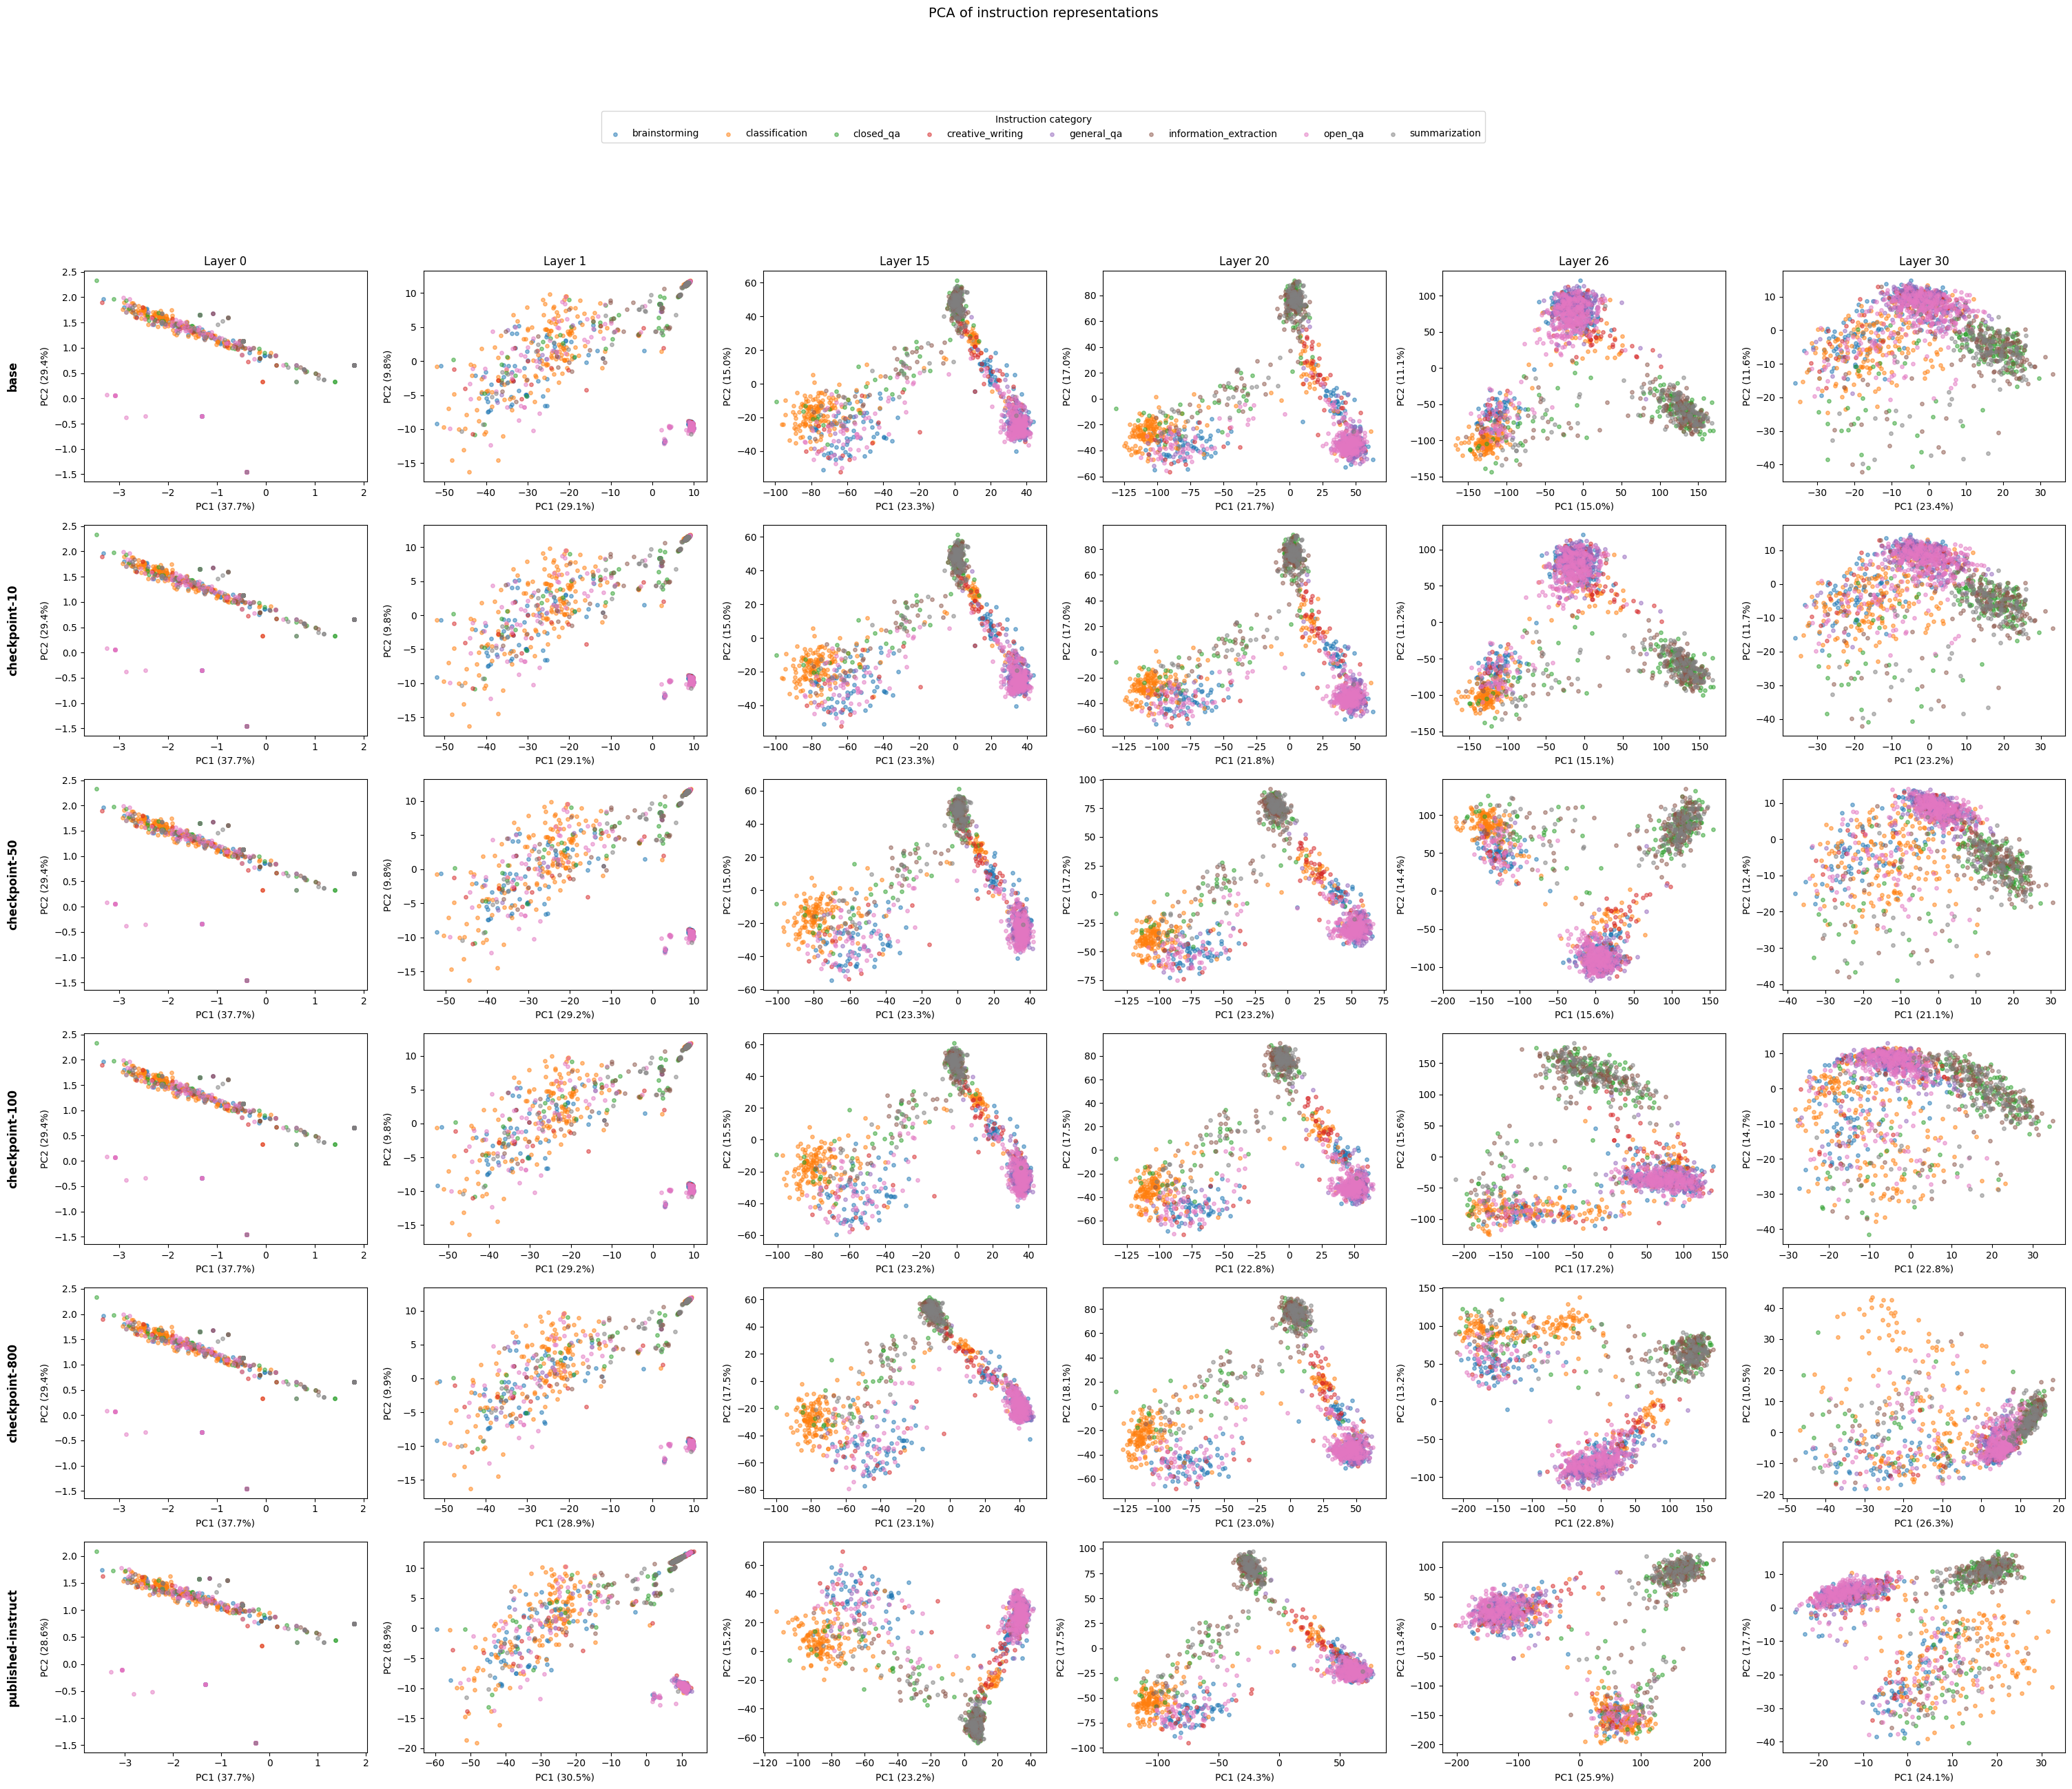

In [ ]:
selected_models = ["base", "checkpoint-10", "checkpoint-50", "checkpoint-100", "checkpoint-800", "published-instruct"]
selected_layers = [0, 1, 15, 20, 26, 30] # 1, 15, 25, 30
plot_pca_grid(representation_dir, models_to_evaluate, selected_models, selected_layers, representation_type="last_token")

In [ ]:
def plot_pca_grid(representation_dir, model_files, selected_models, selected_layers, representation_type="last_token"):
    first_data = np.load(os.path.join(representation_dir, model_files[selected_models[0]]))
    labels = first_data["labels"]
    unique_labels = np.unique(labels)

    model_representations = {}

    for model_name in selected_models:
        data = np.load(os.path.join(representation_dir, model_files[model_name]))
        assert np.array_equal(data["labels"], labels), f"Labels differ for {model_name}."
        model_representations[model_name] = data[representation_type]

    fig, axes = plt.subplots(len(selected_models), len(selected_layers), figsize=(4 * len(selected_layers), 4 * len(selected_models)), squeeze=False)

    legend_handles = []
    legend_labels = []

    for col, layer in enumerate(selected_layers):
        X_combined = np.concatenate([model_representations[model_name][:, layer, :] for model_name in selected_models], axis=0)

        pca = PCA(n_components=2)
        pca.fit(X_combined)

        transformed_representations = {}

        for model_name in selected_models:
            X = model_representations[model_name][:, layer, :]
            transformed_representations[model_name] = pca.transform(X)

        all_reduced = np.concatenate(list(transformed_representations.values()), axis=0)

        x_min = all_reduced[:, 0].min()
        x_max = all_reduced[:, 0].max()
        y_min = all_reduced[:, 1].min()
        y_max = all_reduced[:, 1].max()

        x_margin = 0.05 * (x_max - x_min)
        y_margin = 0.05 * (y_max - y_min)

        for row, model_name in enumerate(selected_models):
            ax = axes[row, col]
            reduced_representations = transformed_representations[model_name]

            for label in unique_labels:
                mask = labels == label
                scatter = ax.scatter(reduced_representations[mask, 0], reduced_representations[mask, 1], label=label, alpha=0.5, s=15)

                if row == 0 and col == 0:
                    legend_handles.append(scatter)
                    legend_labels.append(label)

            ax.set_xlim(x_min - x_margin, x_max + x_margin)
            ax.set_ylim(y_min - y_margin, y_max + y_margin)

            ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
            ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")

            if row == 0:
                ax.set_title(f"Layer {layer}")

            if col == 0:
                ax.text(-0.25, 0.5, model_name, transform=ax.transAxes, rotation=90, va="center", ha="center", fontsize=12, fontweight="bold")

    fig.legend(legend_handles, legend_labels, title="Instruction category", loc="upper center", bbox_to_anchor=(0.5, 0.985), ncol=len(unique_labels))
    #fig.suptitle("PCA of instruction representations", fontsize=14, y=1.08)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(f"{representation_dir}/pca_4models_last-token.png", dpi=600, bbox_inches="tight")
    plt.show()

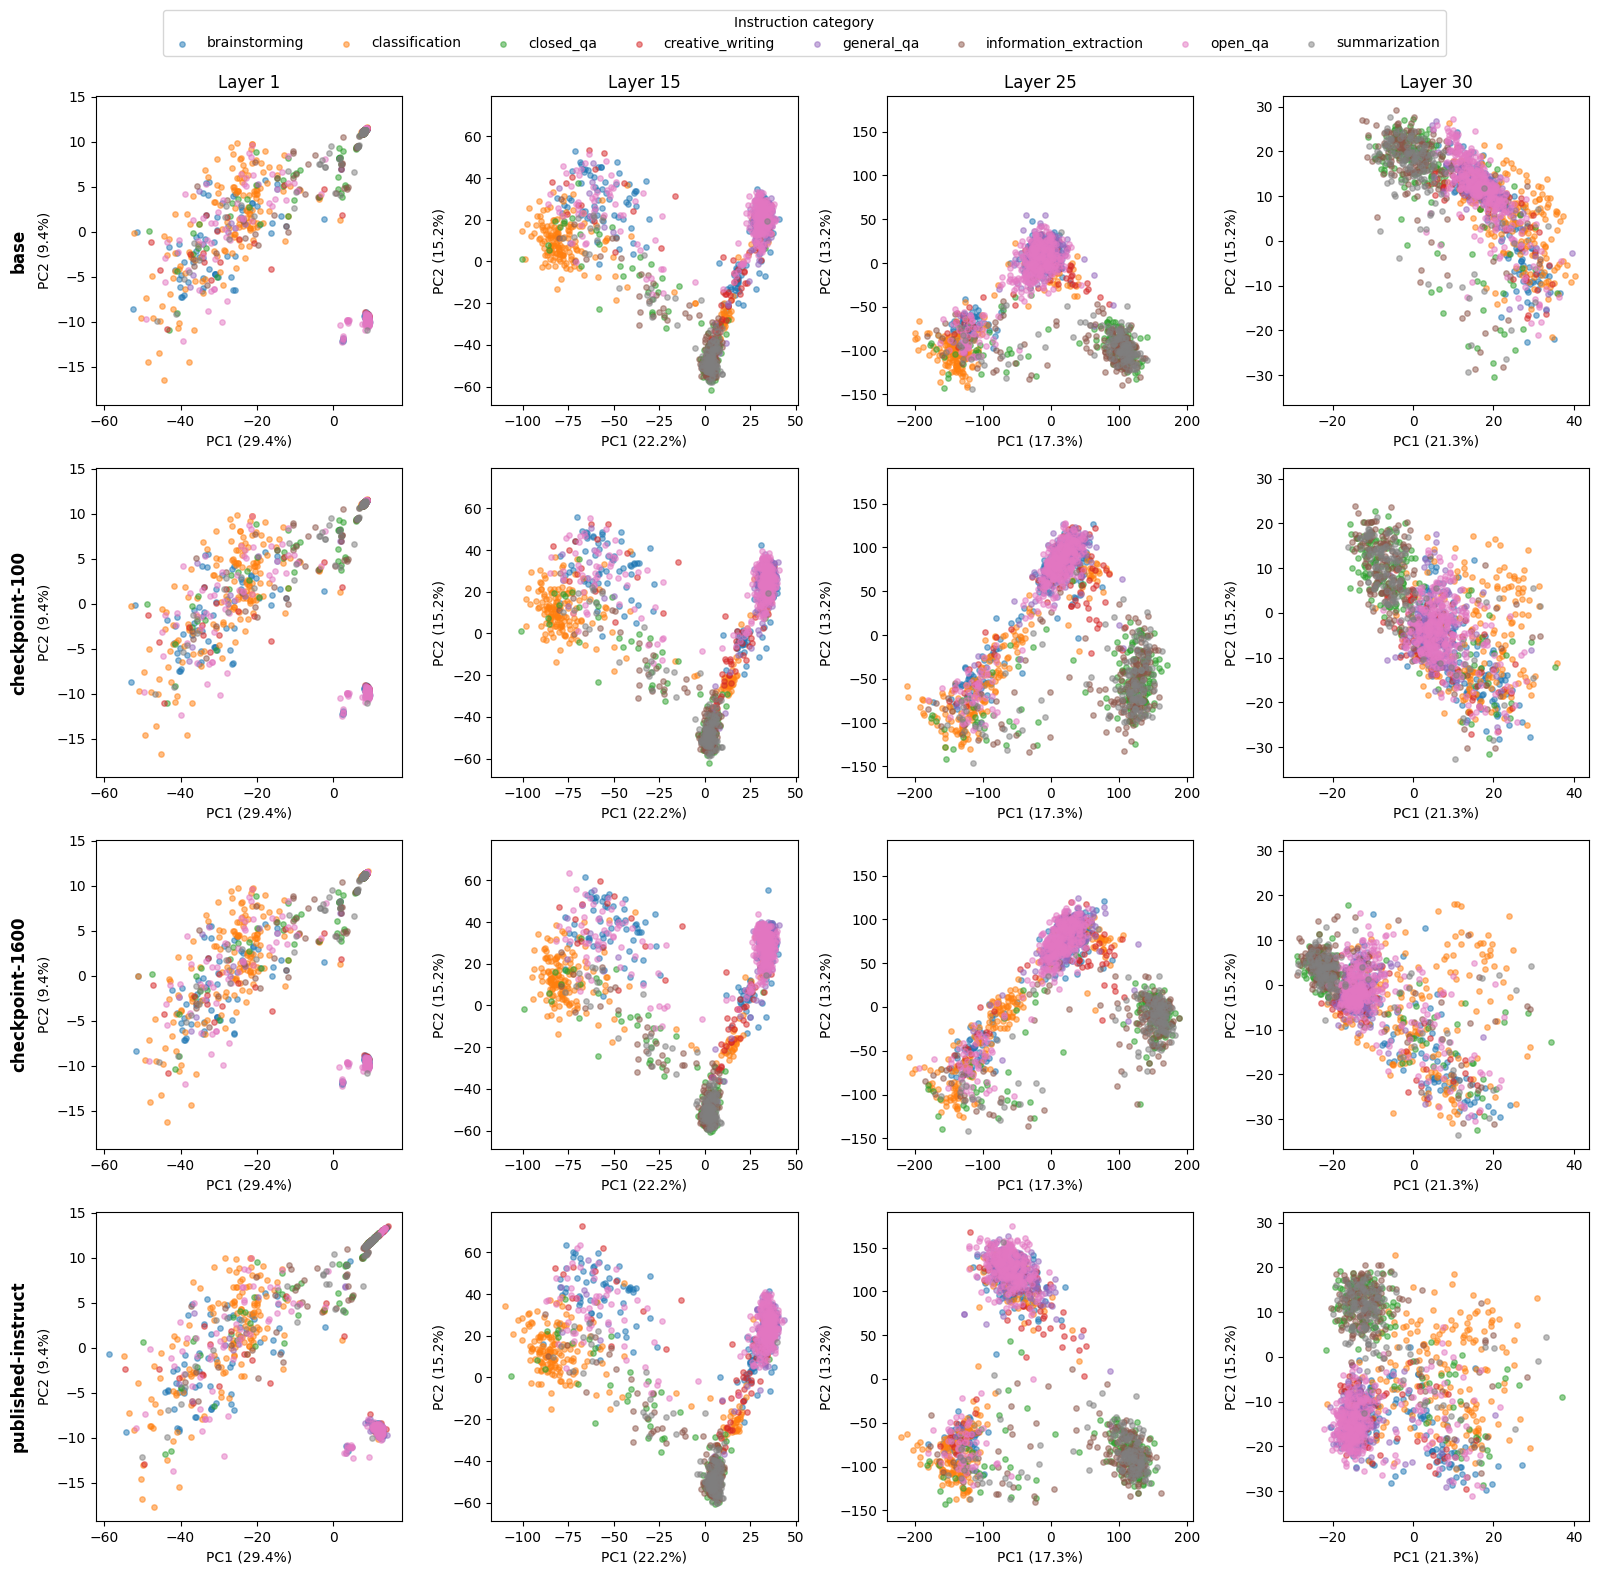

In [ ]:
#selected_models = ["base", "checkpoint-10", "checkpoint-50", "checkpoint-100", "checkpoint-400", "checkpoint-800", "checkpoint-1600", "published-instruct"]
selected_models = ["base", "checkpoint-100", "checkpoint-1600", "published-instruct"]
selected_layers = [1, 15, 25, 30] # 1, 15, 25, 30
plot_pca_grid(representation_dir, models_to_evaluate, selected_models, selected_layers, representation_type="last_token")